# Impact of Automation and AI on Jobs in the United States: reproducible analysis

**Author:** Jude Obidi  
**Origin:** MSc Data Analytics and Technology dissertation, University of Bolton (August 2023), *Impact of Automation and Artificial Intelligence on Jobs in Developed Nations (US)*.

This notebook is a cleaned, reproducible version of the dissertation's analysis. It keeps the original approach (merge Frey & Osborne automation probabilities with BLS occupational employment and wage data, explore it, answer four research questions, and compare linear regression, random forest and gradient boosting) and corrects the errors found while re-running it. Every correction is flagged in a **Correction** note.

**Research questions**
1. Which jobs are most prone to automation?
2. How does automation risk vary across occupational groups ("industries")?
3. Does automation risk differ between US states?
4. Can machine learning predict an occupation's automation risk, and which model works best?

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from automation_risk import RANDOM_STATE, HIGH_RISK_THRESHOLD
from automation_risk import data, analysis, models, replicate

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="notebook")
ACCENT, ACCENT2, GREY = "#C0392B", "#1F618D", "#7F8C8D"

def short(names, n=48):
    names = names.str.replace("; ", ", ", regex=False)
    return names.where(names.str.len() <= n, names.str.slice(0, n - 1) + "…")

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data

| File (in `data/`) | Content | Source |
|---|---|---|
| `automation_data_by_state.csv` | 702 occupations (SOC code), probability of computerisation, employment in each of the 50 states + DC | Kaggle, *Occupation, Salary and Likelihood of Automation* (probabilities from Frey & Osborne, 2017; state employment from BLS) |
| `occupation_salary.xlsx` | National employment and wage estimates by occupation | Same Kaggle dataset; values match the BLS Occupational Employment Statistics (OES) national release for May 2016 |

The data files are not stored in this repository (see `data/README.md`); run `python scripts/download_data.py` first.

In [2]:
auto = data.load_automation()
salary_raw = data.load_salary_raw()
merged_raw = data.merge_raw()          # inner join on OCC_CODE, as in the dissertation
df = data.clean_merged(merged_raw)     # numeric parsing: commas removed, '#' top-coded, '*' -> NaN

print(f"Automation table: {auto.shape[0]} occupations x {auto.shape[1]} columns")
print(f"Salary table:     {salary_raw.shape[0]} rows (all SOC levels)")
print(f"Merged table:     {df.shape[0]} occupations")
unmatched = auto.loc[~auto.OCC_CODE.isin(salary_raw.OCC_CODE), ["OCC_CODE", "Occupation"]]
print(f"\n{len(unmatched)} occupations in the automation table have no match in the salary table:")
unmatched

Automation table: 702 occupations x 54 columns
Salary table:     1394 rows (all SOC levels)
Merged table:     688 occupations

14 occupations in the automation table have no match in the salary table:


,OCC_CODE,Occupation
40,13-1078,Human Resources; Training; and Labor Relations...
69,15-1179,Information Security Analysts; Web Developers;...
70,15-1799,Computer Occupations; All Other
185,25-3999,Teachers and Instructors; All Other
242,29-1111,Registered Nurses
258,29-2037,Radiologic Technologists and Technicians
270,29-2799,Health Technologists and Technicians; All Other
274,29-9799,Healthcare Practitioners and Technical Workers...
288,31-9799,Healthcare Support Workers; All Other
346,39-4831,Funeral Service Managers; Directors; Mortician...


**Data notes.** BLS marks wages at or above the top-code ($208,000 a year / $100 an hour in 2016) with `#` and unavailable estimates with `*`. The original notebook turned these into missing values and filled them with the column mean. Here `#` is set to the top-code (a lower bound) and `*` is left missing and imputed with the training-set median inside the model pipeline.

For the descriptive questions (1 to 3), employment comes from the state columns of the automation table (the sum across 51 states). The Kaggle dataset records occupations with unavailable data or fewer than 10 workers in a state as 0, and 19 occupations have zero employment in every state, including **Registered Nurses** and **Physicians and Surgeons** (their codes differ between sources). Employment-weighted figures therefore leave these occupations out.

In [3]:
occ = analysis.automation_with_employment(auto)
print("Occupations with zero employment in all states:", int((occ.EMPLOYMENT == 0).sum()))
print(f"Employment covered: {occ.EMPLOYMENT.sum():,.0f} jobs")
occ[["Probability", "EMPLOYMENT"]].describe().round(3)

Occupations with zero employment in all states: 19
Employment covered: 125,099,130 jobs


,Probability,EMPLOYMENT
count,702.000,702.000
mean,0.536,178203.889
std,0.368,419571.279
min,0.003,0.000
25%,0.110,13985.000
50%,0.640,44810.000
75%,0.890,144205.000
max,0.990,4528570.000


## 2. Exploratory analysis

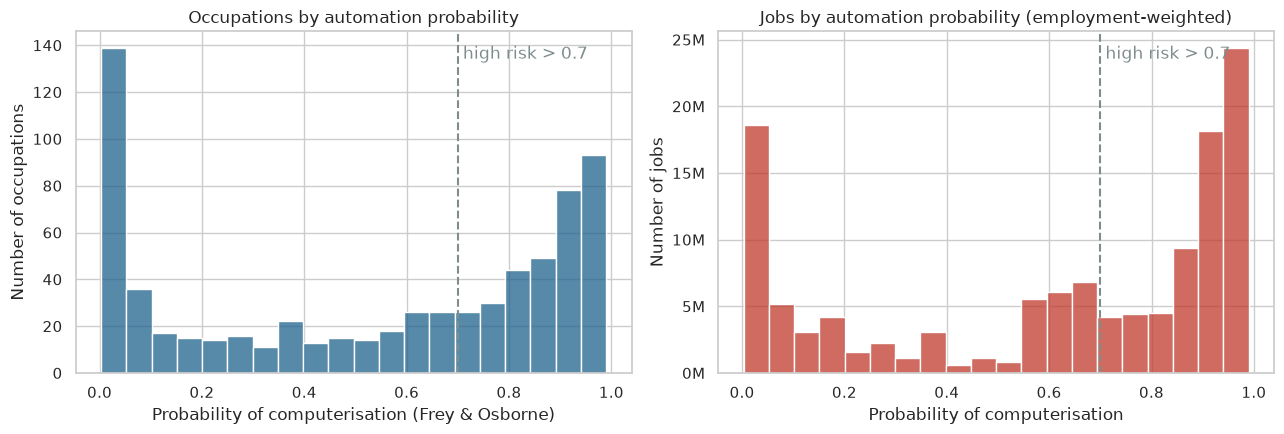

Employment-weighted mean probability: 0.606
Share of covered jobs in occupations with probability > 0.7: 51.7%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(occ["Probability"], bins=20, ax=axes[0], color=ACCENT2)
axes[0].set(title="Occupations by automation probability", xlabel="Probability of computerisation (Frey & Osborne)", ylabel="Number of occupations")
sns.histplot(occ, x="Probability", weights="EMPLOYMENT", bins=20, ax=axes[1], color=ACCENT)
axes[1].set(title="Jobs by automation probability (employment-weighted)", xlabel="Probability of computerisation", ylabel="Number of jobs")
axes[1].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1e6:.0f}M"))
for ax in axes: ax.axvline(HIGH_RISK_THRESHOLD, ls="--", color=GREY); ax.text(HIGH_RISK_THRESHOLD + 0.01, ax.get_ylim()[1]*0.92, "high risk > 0.7", color=GREY)
fig.tight_layout(); save(fig, "01_probability_distribution.png")

w = (occ.Probability * occ.EMPLOYMENT).sum() / occ.EMPLOYMENT.sum()
hr = occ.loc[occ.Probability > HIGH_RISK_THRESHOLD, "EMPLOYMENT"].sum() / occ.EMPLOYMENT.sum()
print(f"Employment-weighted mean probability: {w:.3f}")
print(f"Share of covered jobs in occupations with probability > {HIGH_RISK_THRESHOLD}: {hr:.1%}")

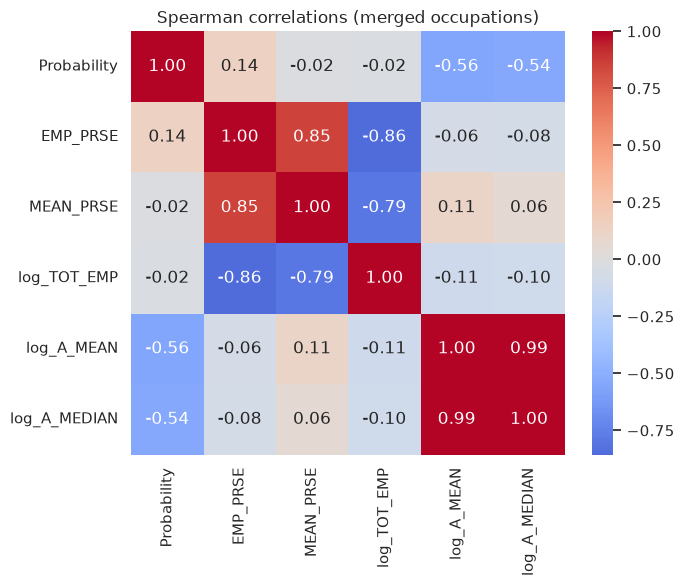

In [5]:
num = df[["Probability", "TOT_EMP", "A_MEAN", "A_MEDIAN", "EMP_PRSE", "MEAN_PRSE"]].copy()
num["log_TOT_EMP"] = np.log1p(num.pop("TOT_EMP")); num["log_A_MEAN"] = np.log(num.pop("A_MEAN")); num["log_A_MEDIAN"] = np.log(num.pop("A_MEDIAN"))
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlations (merged occupations)")
save(fig, "02_correlation_heatmap.png")

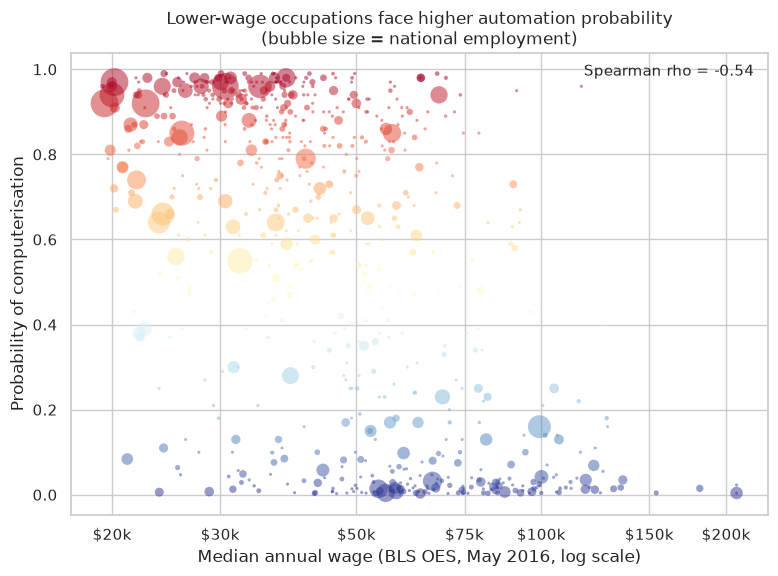

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
plot = df.dropna(subset=["A_MEDIAN"])
sc = ax.scatter(plot["A_MEDIAN"], plot["Probability"], s=np.clip(plot["TOT_EMP"] / 8000, 5, 400), alpha=0.5, c=plot["Probability"], cmap="RdYlBu_r", edgecolor="none")
ax.set_xscale("log")
ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([20000, 30000, 50000, 75000, 100000, 150000, 200000]))
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set(xlabel="Median annual wage (BLS OES, May 2016, log scale)", ylabel="Probability of computerisation", title="Lower-wage occupations face higher automation probability\n(bubble size = national employment)")
rho = plot[["A_MEDIAN", "Probability"]].corr(method="spearman").iloc[0, 1]
ax.text(0.98, 0.95, f"Spearman rho = {rho:.2f}", transform=ax.transAxes, ha="right", fontsize=11)
save(fig, "03_wage_vs_probability.png")

## 3. RQ1: Which jobs are most prone to automation?

Two views: the occupations with the **highest probability**, and the occupations with the **most jobs exposed** (employment x probability). The second is what the dissertation's "Retail Salespersons 9.36" figure was trying to show.

> **Correction.** The original exposure score multiplied *standardised* employment (a z-score) by the probability, giving values such as 9.36 that have no unit and can be negative. Here exposure is computed from raw employment, so it reads as "jobs in the occupation x probability of computerisation". It is an exposure index, not a forecast of jobs that will be lost. The original also labelled the 10 *lowest*-probability occupations as "Most Sensitive"; the labels are corrected here.

In [7]:
cols = ["OCC_CODE", "Occupation", "Probability", "EMPLOYMENT"]
highest = occ.sort_values(["Probability", "EMPLOYMENT"], ascending=False).head(15)[cols]
lowest = occ.sort_values(["Probability", "EMPLOYMENT"], ascending=[True, False]).head(15)[cols]
exposed = occ.sort_values("EXPOSED_EMPLOYMENT", ascending=False).head(15)[cols + ["EXPOSED_EMPLOYMENT"]]
print("Highest automation probability"); display(highest.reset_index(drop=True))
print("Lowest automation probability"); display(lowest.reset_index(drop=True))
print("Largest exposed employment"); display(exposed.reset_index(drop=True).style.format({"EMPLOYMENT": "{:,.0f}", "EXPOSED_EMPLOYMENT": "{:,.0f}"}))
pd.concat([highest.assign(list="highest_probability"), lowest.assign(list="lowest_probability"), exposed.assign(list="largest_exposed_employment")]).to_csv(RES / "rq1_occupations.csv", index=False)

Highest automation probability


,OCC_CODE,Occupation,Probability,EMPLOYMENT
0,41-9041,Telemarketers,0.99,214570
1,43-9021,Data Entry Keyers,0.99,193890
2,25-4031,Library Technicians,0.99,93400
3,13-2053,Insurance Underwriters,0.99,90310
4,43-5011,Cargo and Freight Agents,0.99,88910
5,13-2082,Tax Preparers,0.99,63600
6,23-2093,Title Examiners; Abstractors; and Searchers,0.99,51810
7,43-4141,New Accounts Clerks,0.99,41430
8,51-9151,Photographic Process Workers and Processing Ma...,0.99,26200
9,51-6051,Sewers; Hand,0.99,5170


Lowest automation probability


,OCC_CODE,Occupation,Probability,EMPLOYMENT
0,29-1125,Recreational Therapists,0.0028,18080
1,49-1011,First-Line Supervisors of Mechanics; Installer...,0.0030,453360
2,11-9161,Emergency Management Directors,0.0030,9540
3,21-1023,Mental Health and Substance Abuse Social Workers,0.0031,111370
4,29-1181,Audiologists,0.0033,11830
5,21-1022,Healthcare Social Workers,0.0035,159340
6,29-1122,Occupational Therapists,0.0035,118060
7,29-2091,Orthotists and Prosthetists,0.0035,6260
8,33-1021,First-Line Supervisors of Fire Fighting and Pr...,0.0036,56980
9,29-1022,Oral and Maxillofacial Surgeons,0.0036,3450


Largest exposed employment


,OCC_CODE,Occupation,Probability,EMPLOYMENT,EXPOSED_EMPLOYMENT
0,41-2031,Retail Salespersons,0.920000,"4,528,570","4,166,284"
1,41-2011,Cashiers,0.970000,"3,540,980","3,434,751"
2,35-3021,Combined Food Preparation and Serving Workers; Including Fast Food,0.920000,"3,426,090","3,152,003"
3,43-9061,Office Clerks; General,0.960000,"2,955,560","2,837,338"
4,35-3031,Waiters and Waitresses,0.940000,"2,564,620","2,410,743"
5,43-6014,Secretaries and Administrative Assistants; Except Legal; Medical; and Executive,0.960000,"2,295,480","2,203,661"
6,53-7062,Laborers and Freight; Stock; and Material Movers; Hand,0.850000,"2,587,940","2,199,749"
7,43-3031,Bookkeeping; Accounting; and Auditing Clerks,0.980000,"1,566,970","1,535,631"
8,43-4051,Customer Service Representatives,0.550000,"2,707,030","1,488,867"
9,37-2011,Janitors and Cleaners; Except Maids and Housekeeping Cleaners,0.660000,"2,161,710","1,426,729"


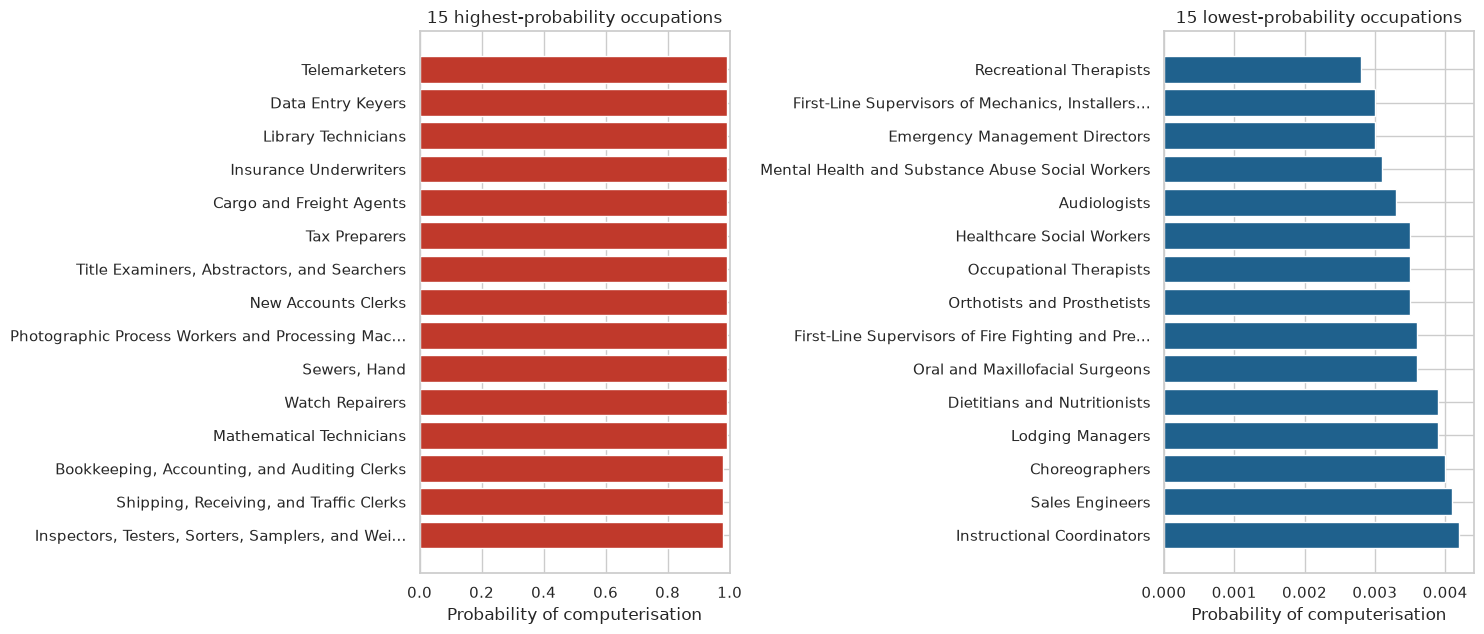

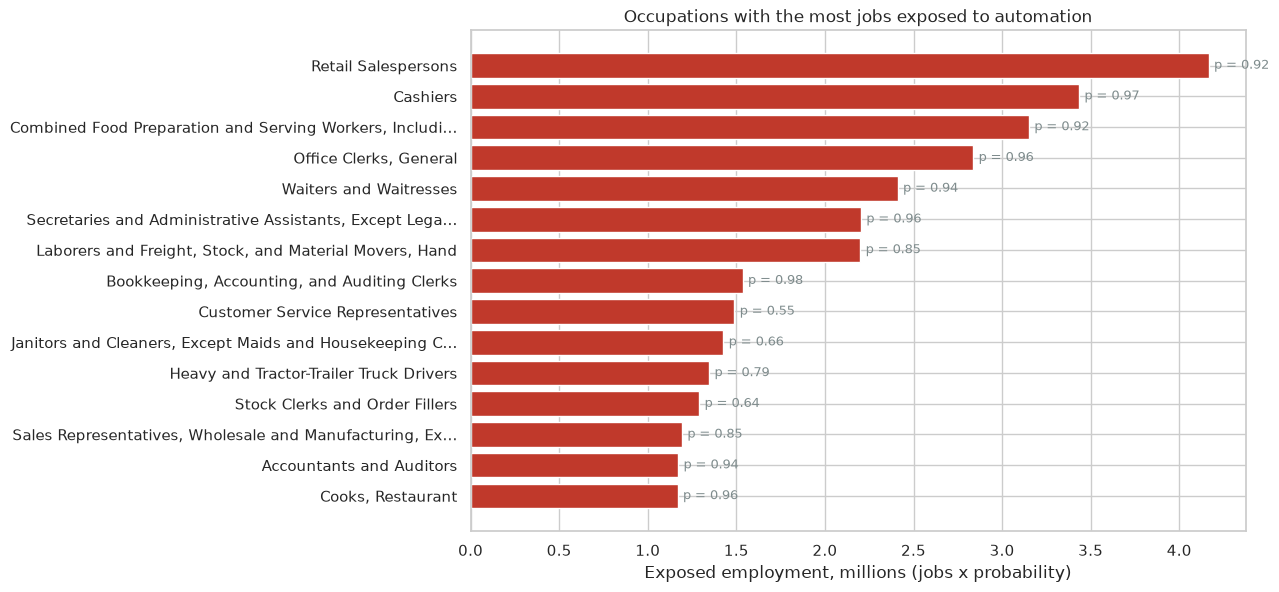

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
h = highest.iloc[::-1]; l = lowest.iloc[::-1]
axes[0].barh(short(h["Occupation"]), h["Probability"], color=ACCENT); axes[0].set(xlim=(0, 1), xlabel="Probability of computerisation", title="15 highest-probability occupations")
axes[1].barh(short(l["Occupation"]), l["Probability"], color=ACCENT2); axes[1].set(xlabel="Probability of computerisation", title="15 lowest-probability occupations")
fig.tight_layout(); save(fig, "04_highest_lowest_probability.png")

fig, ax = plt.subplots(figsize=(10, 6.5))
e = exposed.iloc[::-1]
ax.barh(short(e["Occupation"], 55), e["EXPOSED_EMPLOYMENT"] / 1e6, color=ACCENT)
for y, (v, p) in enumerate(zip(e["EXPOSED_EMPLOYMENT"] / 1e6, e["Probability"])):
    ax.text(v + 0.03, y, f"p = {p:.2f}", va="center", fontsize=9, color=GREY)
ax.set(xlabel="Exposed employment, millions (jobs x probability)", title="Occupations with the most jobs exposed to automation")
save(fig, "05_largest_exposed_employment.png")

## 4. RQ2: How does risk vary across occupational groups?

> **Correction.** The dissertation grouped by the BLS `OCC_GROUP` column, whose values (`detailed`, `broad`, `minor`) are levels of the SOC hierarchy, not industries, and averaged the standardised exposure score. Here occupations are grouped by their **SOC major group** (the first two digits of the SOC code, e.g. 31 = Healthcare Support), and both the simple and the employment-weighted mean probability are reported, along with the share of jobs in high-risk occupations (probability > 0.7). The data are by occupation, not by industry, so these are occupational groups.

In [9]:
groups = analysis.major_group_summary(occ)
groups.to_csv(RES / "rq2_major_groups.csv")
groups.style.format({"employment": "{:,.0f}", "mean_probability_unweighted": "{:.3f}", "mean_probability_emp_weighted": "{:.3f}", "share_emp_high_risk": "{:.1%}"})

,occupations,employment,mean_probability_unweighted,mean_probability_emp_weighted,share_emp_high_risk
SOC_MAJOR_NAME,,,,,
Food Preparation & Serving,16,"12,906,870",0.784,0.877,91.9%
Sales & Related,20,"13,491,240",0.648,0.801,81.5%
Production,103,"8,389,360",0.824,0.794,73.8%
Office & Administrative Support,52,"21,577,910",0.838,0.793,67.4%
Transportation & Material Moving,48,"9,468,840",0.684,0.743,71.1%
Building & Grounds Cleaning & Maintenance,8,"4,391,060",0.776,0.737,25.7%
"Farming, Fishing & Forestry",11,"109,710",0.794,0.650,48.6%
Construction & Extraction,56,"5,475,450",0.733,0.639,63.9%
"Installation, Maintenance & Repair",50,"5,256,860",0.675,0.579,22.8%


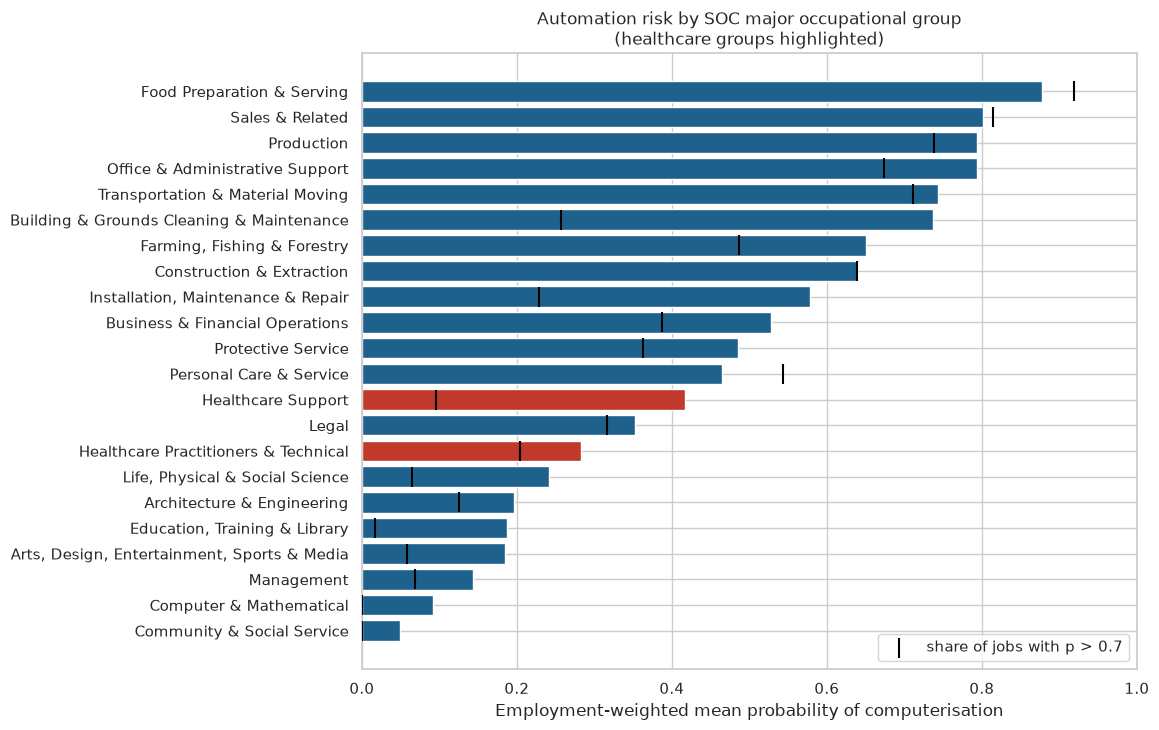

In [10]:
g = groups.sort_values("mean_probability_emp_weighted")
fig, ax = plt.subplots(figsize=(10, 8))
colors = [ACCENT if "Health" in n else ACCENT2 for n in g.index]
ax.barh(g.index, g["mean_probability_emp_weighted"], color=colors)
ax.scatter(g["share_emp_high_risk"], g.index, color="black", marker="|", s=200, zorder=3, label="share of jobs with p > 0.7")
ax.set(xlim=(0, 1), xlabel="Employment-weighted mean probability of computerisation", title="Automation risk by SOC major occupational group\n(healthcare groups highlighted)")
ax.legend(loc="lower right")
save(fig, "06_major_group_risk.png")

## 5. RQ3: Does risk differ between states?

> **Correction.** The dissertation reported California as having "the higher job loss probability of 20,585.89". That number is the **average number of workers per occupation** in California (the mean of the state's employment column), so it ranks states by size, not by risk. The value is reproduced below to show where it came from. The corrected metric is the employment-weighted mean automation probability for each state: sum over occupations of (state employment x probability) / state employment. The share of each state's jobs in high-risk occupations is also reported.

In [11]:
orig_metric = analysis.original_state_metric(merged_raw)
print("Original metric (mean employment per occupation, NOT a probability), top 5:")
print(orig_metric.head(5).round(2).to_string())

states = analysis.state_summary(occ)
states.to_csv(RES / "rq3_states.csv", index=False)
print(f"\nCorrected: employment-weighted probability ranges from {states.emp_weighted_probability.min():.3f} "
      f"({states.iloc[-1].state}) to {states.emp_weighted_probability.max():.3f} ({states.iloc[0].state}); "
      f"spread = {states.emp_weighted_probability.max() - states.emp_weighted_probability.min():.3f}")
display(states.head(10).style.format({"employment_covered": "{:,.0f}", "workers_in_high_risk_occupations": "{:,.0f}", "emp_weighted_probability": "{:.3f}", "share_emp_high_risk": "{:.1%}"}))
display(states.tail(10).style.format({"employment_covered": "{:,.0f}", "workers_in_high_risk_occupations": "{:,.0f}", "emp_weighted_probability": "{:.3f}", "share_emp_high_risk": "{:.1%}"}))
print("California rank (corrected):", int(states.index[states.state == "California"][0]) + 1, "of 51")

Original metric (mean employment per occupation, NOT a probability), top 5:
California      20585.89
Texas           15530.84
New York        11845.22
Florida         10682.18
Pennsylvania     7514.24

Corrected: employment-weighted probability ranges from 0.445 (District of Columbia) to 0.665 (Nevada); spread = 0.219


,state,employment_covered,emp_weighted_probability,share_emp_high_risk,workers_in_high_risk_occupations
0,Nevada,"1,140,240",0.665,58.1%,"662,630"
1,South Dakota,"378,530",0.656,58.5%,"221,290"
2,Alabama,"1,722,020",0.640,55.8%,"960,070"
3,Indiana,"2,684,160",0.637,55.5%,"1,488,410"
4,Kentucky,"1,650,310",0.635,55.1%,"910,030"
5,Florida,"7,349,340",0.633,53.9%,"3,963,680"
6,Mississippi,"1,003,550",0.632,54.5%,"546,730"
7,Louisiana,"1,722,150",0.630,54.9%,"946,150"
8,South Carolina,"1,801,950",0.629,54.1%,"974,380"
9,Montana,"401,890",0.629,54.7%,"219,960"


,state,employment_covered,emp_weighted_probability,share_emp_high_risk,workers_in_high_risk_occupations
41,Minnesota,"2,501,100",0.593,50.7%,"1,268,720"
42,New Jersey,"3,474,620",0.591,49.6%,"1,722,000"
43,Washington,"2,726,240",0.590,50.0%,"1,364,040"
44,Colorado,"2,212,180",0.589,49.8%,"1,101,050"
45,Virginia,"3,270,730",0.580,48.8%,"1,595,730"
46,New York,"8,149,510",0.580,48.3%,"3,937,760"
47,Connecticut,"1,475,400",0.568,47.4%,"699,940"
48,Maryland,"2,306,300",0.561,46.7%,"1,077,100"
49,Massachusetts,"3,069,190",0.545,45.2%,"1,388,790"
50,District of Columbia,"599,560",0.445,34.1%,"204,680"


California rank (corrected): 41 of 51


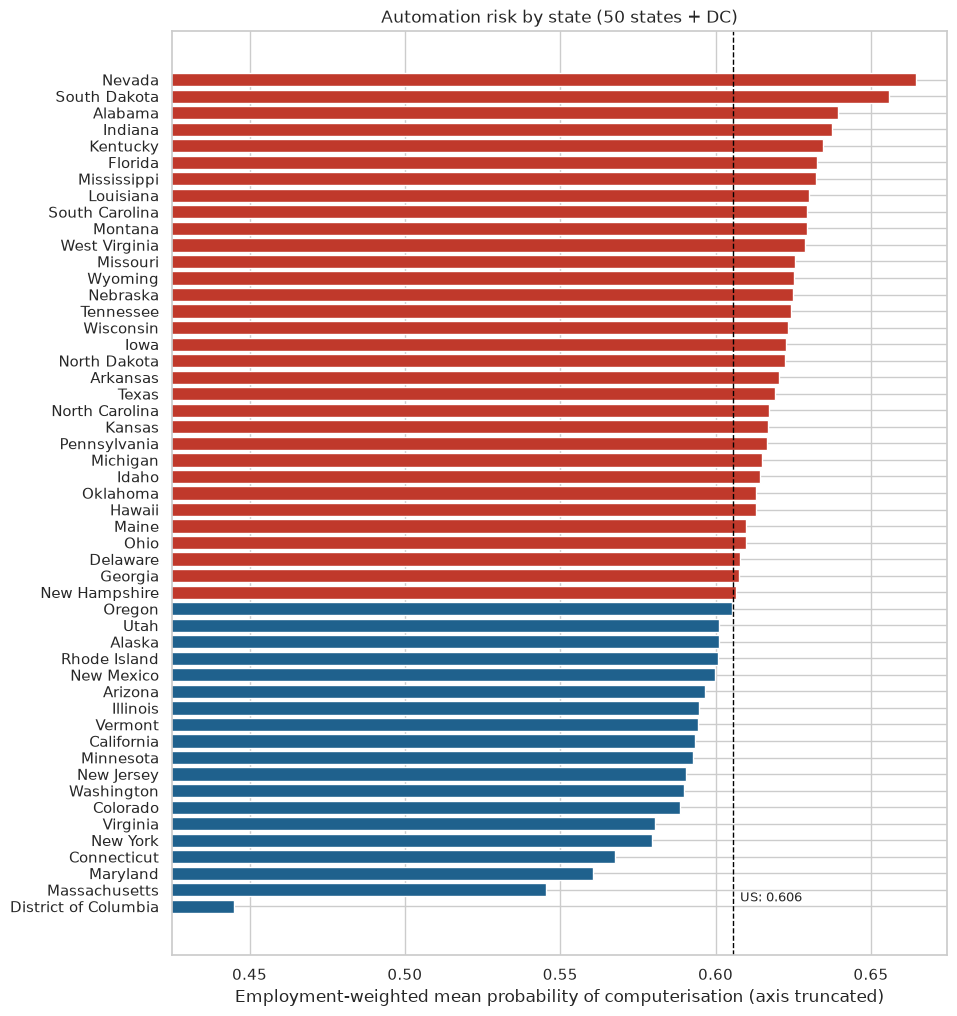

States with the most workers in high-risk occupations (driven by state size):
         state  workers_in_high_risk_occupations  share_emp_high_risk
    California                           7205790             0.508772
         Texas                           5716320             0.534974
       Florida                           3963680             0.539325
      New York                           3937760             0.483190
  Pennsylvania                           2756130             0.533121
      Illinois                           2573020             0.497815
          Ohio                           2466610             0.519691
       Georgia                           1973420             0.519655
      Michigan                           1972160             0.524830
North Carolina                           1965610             0.522685


In [12]:
s = states.sort_values("emp_weighted_probability")
fig, ax = plt.subplots(figsize=(10, 12))
national = (occ.Probability * occ.EMPLOYMENT).sum() / occ.EMPLOYMENT.sum()
ax.barh(s["state"], s["emp_weighted_probability"], color=[ACCENT if v > national else ACCENT2 for v in s["emp_weighted_probability"]])
ax.axvline(national, color="black", ls="--", lw=1); ax.text(national + 0.001, 0.3, f" US: {national:.3f}", fontsize=9)
lo = s["emp_weighted_probability"].min(); hi = s["emp_weighted_probability"].max()
ax.set(xlim=(lo - 0.02, hi + 0.01), xlabel="Employment-weighted mean probability of computerisation (axis truncated)", title="Automation risk by state (50 states + DC)")
save(fig, "07_state_weighted_probability.png")

top = states.sort_values("workers_in_high_risk_occupations", ascending=False).head(10)
print("States with the most workers in high-risk occupations (driven by state size):")
print(top[["state", "workers_in_high_risk_occupations", "share_emp_high_risk"]].to_string(index=False))

## 6. RQ4: Can machine learning predict automation risk?

### 6a. Re-running the original model exactly

The original model predicted `Job_Loss_Probability = standardised(TOT_EMP) x Probability`, and used **both** `TOT_EMP` and `Probability` as input features, alongside label-encoded identifiers (occupation code and title) and wage percentiles. Below, that pipeline is re-run unchanged.

In [13]:
orig_now = replicate.run_original_models(merged_raw)
orig_2023 = pd.read_csv(RES / "original_replication_2023_env.csv")
print("Original pipeline, current library versions (see requirements.txt):")
display(orig_now.round(4))
print("Original pipeline, 2023 library versions (requirements-replication-2023.txt; output of src/automation_risk/replicate.py):")
display(orig_2023.round(4))
orig_now.to_csv(RES / "original_replication_current_env.csv", index=False)

Original pipeline, current library versions (see requirements.txt):


,model,test_MSE,test_MAE,test_RMSE,test_R2,cv5_RMSE_mean,cv5_RMSE_std
0,Linear Regression,0.1318,0.1764,0.3630,0.8271,0.3731,0.0863
1,Random Forest,0.0209,0.0410,0.1447,0.9725,0.2726,0.0908
2,Gradient Boosting,0.0212,0.0489,0.1457,0.9721,0.2744,0.1044


Original pipeline, 2023 library versions (requirements-replication-2023.txt; output of src/automation_risk/replicate.py):


,model,test_MSE,test_MAE,test_RMSE,test_R2,cv5_RMSE_mean,cv5_RMSE_std
0,Linear Regression,0.1358,0.1817,0.3685,0.8218,0.3723,0.0836
1,Random Forest,0.0203,0.0414,0.1426,0.9733,0.2758,0.0942
2,Gradient Boosting,0.0235,0.0500,0.1534,0.9691,0.2711,0.1023


With the 2023 library versions (Python 3.11, scikit-learn 1.2.2, pandas 1.5.3) the dissertation's figures are reproduced exactly: linear regression MSE 0.1358, MAE 0.1817, RMSE 0.3685, R-squared 0.8218, and 5-fold CV RMSE of 0.3723 (linear regression), 0.2758 (random forest) and **0.2711 (gradient boosting)**. With current library versions the linear regression scores shift slightly (MSE about 0.132), because the feature matrix is rank-deficient and the least-squares solver changed between versions.

> **Correction (target leakage).** Because the target is computed from two of the input columns, these scores show how well the models re-learn a known formula, not how well they predict automation risk. The target is also not a probability (it is negative for every occupation with below-average employment). These results should not be read as evidence of predictive skill.

### 6b. Corrected model

* **Target:** the occupation's probability of computerisation (0 to 1).
* **Features:** information that does not contain the target: log national employment, log annual wage distribution (mean, 10th, 25th, 50th, 75th and 90th percentiles), the relative standard errors of the employment and wage estimates, and the SOC major group (one-hot encoded). A second run without the major group shows how much the wage and employment data explain alone.
* **Protocol:** the same three model families as the dissertation (plus a predict-the-mean baseline for reference), the same 80/20 train/test split with `random_state=42`, and 5-fold cross-validation on the training set. Imputation and scaling are fitted inside a scikit-learn `Pipeline`, so nothing leaks from the test set.

In [14]:
results, fitted, test = [], {}, {}
for fs in models.FEATURE_SETS:
    r, f, t = models.evaluate(df, fs)
    results.append(r); fitted[fs] = f; test[fs] = t
results = pd.concat(results, ignore_index=True)
results.to_csv(RES / "rq4_model_metrics.csv", index=False)
results.round(4)

,feature_set,model,test_MSE,test_MAE,test_RMSE,test_R2,cv5_RMSE_mean,cv5_RMSE_std
0,labour market + SOC major group,Baseline (predict mean),0.1367,0.3382,0.3697,-0.0049,0.3685,0.0173
1,labour market + SOC major group,Linear Regression,0.0674,0.2047,0.2597,0.5041,0.2542,0.0144
2,labour market + SOC major group,Random Forest,0.0668,0.2032,0.2585,0.5085,0.2677,0.0224
3,labour market + SOC major group,Gradient Boosting,0.0690,0.2078,0.2627,0.4925,0.2707,0.0156
4,labour market only,Baseline (predict mean),0.1367,0.3382,0.3697,-0.0049,0.3685,0.0173
5,labour market only,Linear Regression,0.0833,0.2428,0.2886,0.3874,0.3034,0.0149
6,labour market only,Random Forest,0.0799,0.2279,0.2827,0.4122,0.3044,0.0218
7,labour market only,Gradient Boosting,0.0890,0.2369,0.2983,0.3457,0.3007,0.0162


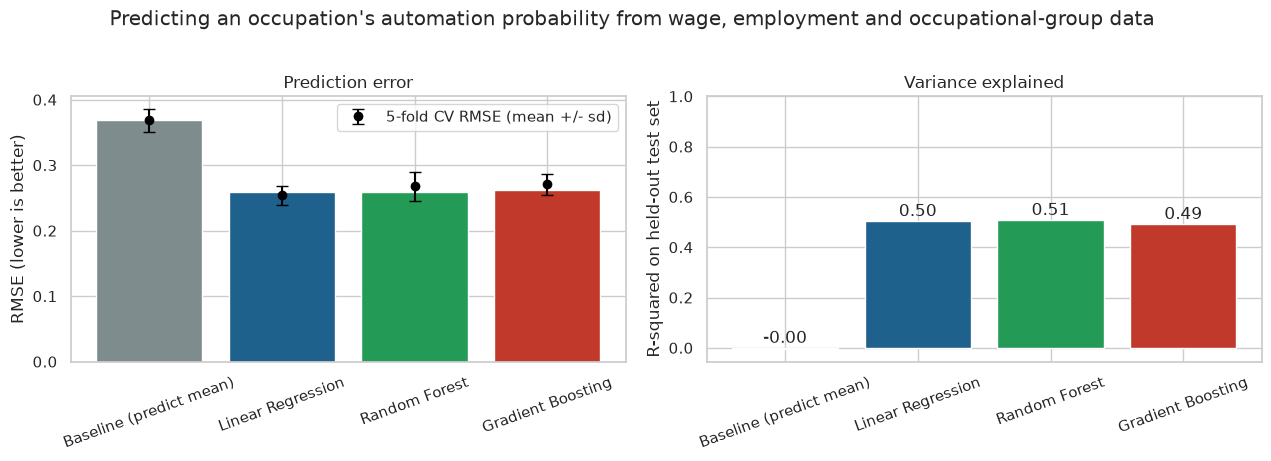

In [15]:
main = results[results.feature_set == "labour market + SOC major group"].set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["Baseline (predict mean)", "Linear Regression", "Random Forest", "Gradient Boosting"]
pal = [GREY, ACCENT2, "#239B56", ACCENT]
axes[0].bar(order, main.loc[order, "test_RMSE"], color=pal)
axes[0].errorbar(order, main.loc[order, "cv5_RMSE_mean"], yerr=main.loc[order, "cv5_RMSE_std"], fmt="o", color="black", capsize=4, label="5-fold CV RMSE (mean +/- sd)")
axes[0].set(ylabel="RMSE (lower is better)", title="Prediction error"); axes[0].legend()
axes[1].bar(order, main.loc[order, "test_R2"], color=pal); axes[1].set(ylabel="R-squared on held-out test set", title="Variance explained", ylim=(min(0, main.test_R2.min()) - 0.05, 1))
for ax in axes: ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(main.loc[order, "test_R2"]): axes[1].text(i, max(v, 0) + 0.02, f"{v:.2f}", ha="center")
fig.suptitle("Predicting an occupation's automation probability from wage, employment and occupational-group data", y=1.02)
fig.tight_layout(); save(fig, "08_model_comparison.png")

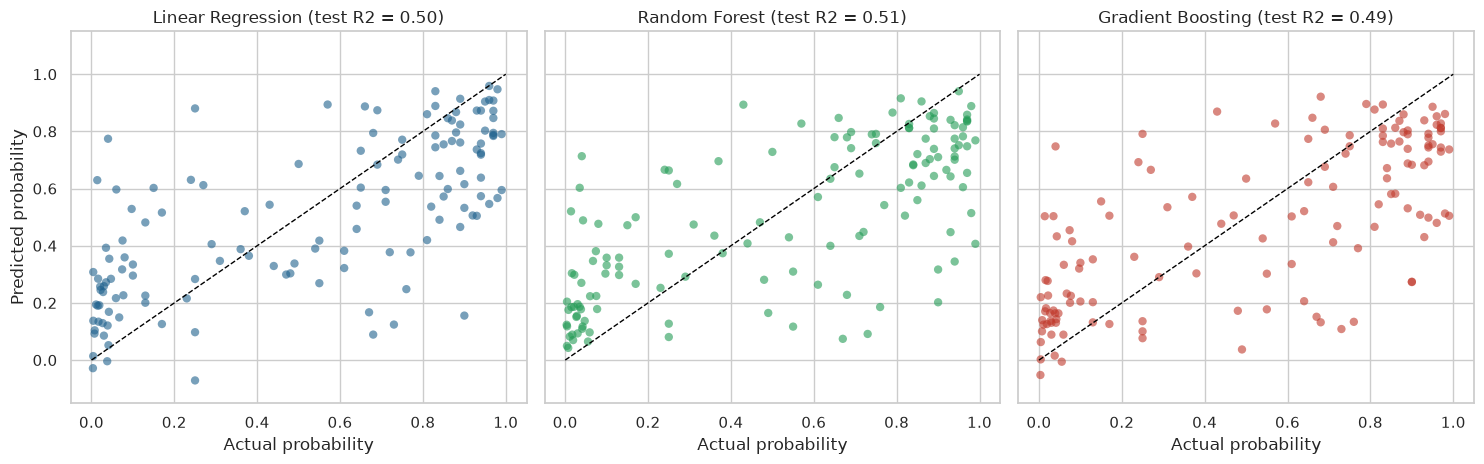

In [16]:
fs = "labour market + SOC major group"
X_te, y_te = test[fs]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, name, col in zip(axes, ["Linear Regression", "Random Forest", "Gradient Boosting"], [ACCENT2, "#239B56", ACCENT]):
    pred = fitted[fs][name].predict(X_te)
    ax.scatter(y_te, pred, alpha=0.6, color=col, edgecolor="none")
    ax.plot([0, 1], [0, 1], ls="--", color="black", lw=1)
    r2 = results.query("feature_set == @fs and model == @name").test_R2.iloc[0]
    ax.set(xlim=(-0.05, 1.05), ylim=(-0.15, 1.15), xlabel="Actual probability", title=f"{name} (test R2 = {r2:.2f})")
axes[0].set_ylabel("Predicted probability")
fig.tight_layout(); save(fig, "09_actual_vs_predicted.png")

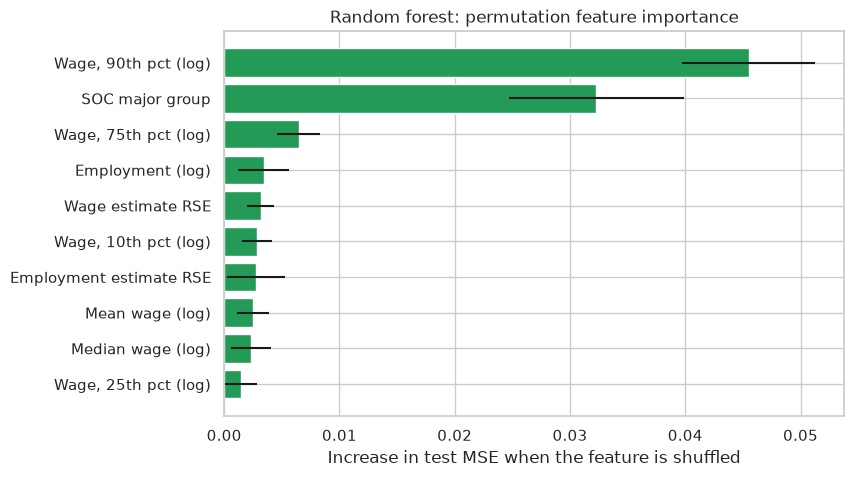

,feature,importance,sd
69,"Wage, 90th pct (log)",0.0455,0.0057
71,SOC major group,0.0323,0.0076
68,"Wage, 75th pct (log)",0.0065,0.0019
55,Employment (log),0.0034,0.0022
59,Wage estimate RSE,0.0032,0.0012
65,"Wage, 10th pct (log)",0.0028,0.0013
56,Employment estimate RSE,0.0028,0.0025
58,Mean wage (log),0.0025,0.0014
67,Median wage (log),0.0023,0.0017
66,"Wage, 25th pct (log)",0.0014,0.0014


In [17]:
from sklearn.inspection import permutation_importance
rf = fitted[fs]["Random Forest"]
pi = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=RANDOM_STATE, scoring="neg_mean_squared_error")
imp = pd.DataFrame({"feature": X_te.columns, "importance": pi.importances_mean, "sd": pi.importances_std})
imp = imp[imp.feature.isin(models.LOG_COLS + models.PLAIN_COLS + models.CAT_COLS)].sort_values("importance")
labels = {"SOC_MAJOR_NAME": "SOC major group", "TOT_EMP": "Employment (log)", "A_MEAN": "Mean wage (log)", "A_PCT10": "Wage, 10th pct (log)", "A_PCT25": "Wage, 25th pct (log)", "A_MEDIAN": "Median wage (log)", "A_PCT75": "Wage, 75th pct (log)", "A_PCT90": "Wage, 90th pct (log)", "EMP_PRSE": "Employment estimate RSE", "MEAN_PRSE": "Wage estimate RSE"}
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.feature.map(labels), imp.importance, xerr=imp.sd, color="#239B56")
ax.set(xlabel="Increase in test MSE when the feature is shuffled", title="Random forest: permutation feature importance")
save(fig, "10_feature_importance.png")
imp.assign(feature=imp.feature.map(labels)).sort_values("importance", ascending=False).round(4)

## 7. Healthcare occupations

This section only describes what the dataset contains for healthcare occupations (SOC 29 and 31, plus Personal Care Aides and Social and Human Service Assistants, which often work in care settings). Registered Nurses (p = 0.009) and Physicians and Surgeons (p = 0.0042) are in the automation table but have no employment counts, so they are excluded from the employment-weighted figures. Nursing Assistants are not in the dataset.

In [18]:
hc = analysis.healthcare_table(occ)
hc.to_csv(RES / "healthcare_occupations.csv", index=False)
for code_, name in [("29", "Healthcare Practitioners & Technical"), ("31", "Healthcare Support")]:
    row = groups.loc[name]
    print(f"{name}: {int(row.occupations)} occupations, {row.employment:,.0f} jobs covered, "
          f"weighted mean p = {row.mean_probability_emp_weighted:.3f}, jobs with p > 0.7 = {row.share_emp_high_risk:.1%}")
print(f"All occupations: weighted mean p = {national:.3f}")

# Sensitivity check: add Registered Nurses back using BLS national employment.
# The automation table codes RNs as 29-1111 (older SOC); the BLS 2016 table uses 29-1141.
rn_emp = data.to_number(salary_raw.loc[salary_raw.OCC_CODE == "29-1141", "TOT_EMP"]).iloc[0]
rn_p = occ.loc[occ.OCC_CODE == "29-1111", "Probability"].iloc[0]
g29 = occ[occ.SOC_MAJOR == "29"]
w_with_rn = ((g29.Probability * g29.EMPLOYMENT).sum() + rn_p * rn_emp) / (g29.EMPLOYMENT.sum() + rn_emp)
print(f"\nSensitivity: adding Registered Nurses (BLS 29-1141, {rn_emp:,.0f} jobs, p = {rn_p}) lowers the "
      f"Healthcare Practitioners & Technical weighted mean from {groups.loc['Healthcare Practitioners & Technical', 'mean_probability_emp_weighted']:.3f} to {w_with_rn:.3f}")
hc.style.format({"Probability": "{:.4f}", "EMPLOYMENT": "{:,.0f}"})

Healthcare Practitioners & Technical: 44 occupations, 4,131,110 jobs covered, weighted mean p = 0.283, jobs with p > 0.7 = 20.3%
Healthcare Support: 14 occupations, 2,329,020 jobs covered, weighted mean p = 0.418, jobs with p > 0.7 = 9.5%
All occupations: weighted mean p = 0.606

Sensitivity: adding Registered Nurses (BLS 29-1141, 2,857,180 jobs, p = 0.009) lowers the Healthcare Practitioners & Technical weighted mean from 0.283 to 0.171


,OCC_CODE,Occupation,SOC_MAJOR_NAME,Probability,EMPLOYMENT
0,29-2052,Pharmacy Technicians,Healthcare Practitioners & Technical,0.9200,"398,410"
1,29-2071,Medical Records and Health Information Technicians,Healthcare Practitioners & Technical,0.9100,"200,130"
2,29-2011,Medical and Clinical Laboratory Technologists,Healthcare Practitioners & Technical,0.9000,"166,730"
3,31-9094,Medical Transcriptionists,Healthcare Support,0.8900,"54,100"
4,31-9096,Veterinary Assistants and Laboratory Animal Caretakers,Healthcare Support,0.8600,"79,790"
5,31-9093,Medical Equipment Preparers,Healthcare Support,0.7800,"52,520"
6,39-9021,Personal Care Aides,Personal Care & Service,0.7400,"1,492,220"
7,31-9095,Pharmacy Aides,Healthcare Support,0.7200,"35,840"
8,29-2081,Opticians; Dispensing,Healthcare Practitioners & Technical,0.7100,"75,240"
9,29-2021,Dental Hygienists,Healthcare Practitioners & Technical,0.6800,"204,990"


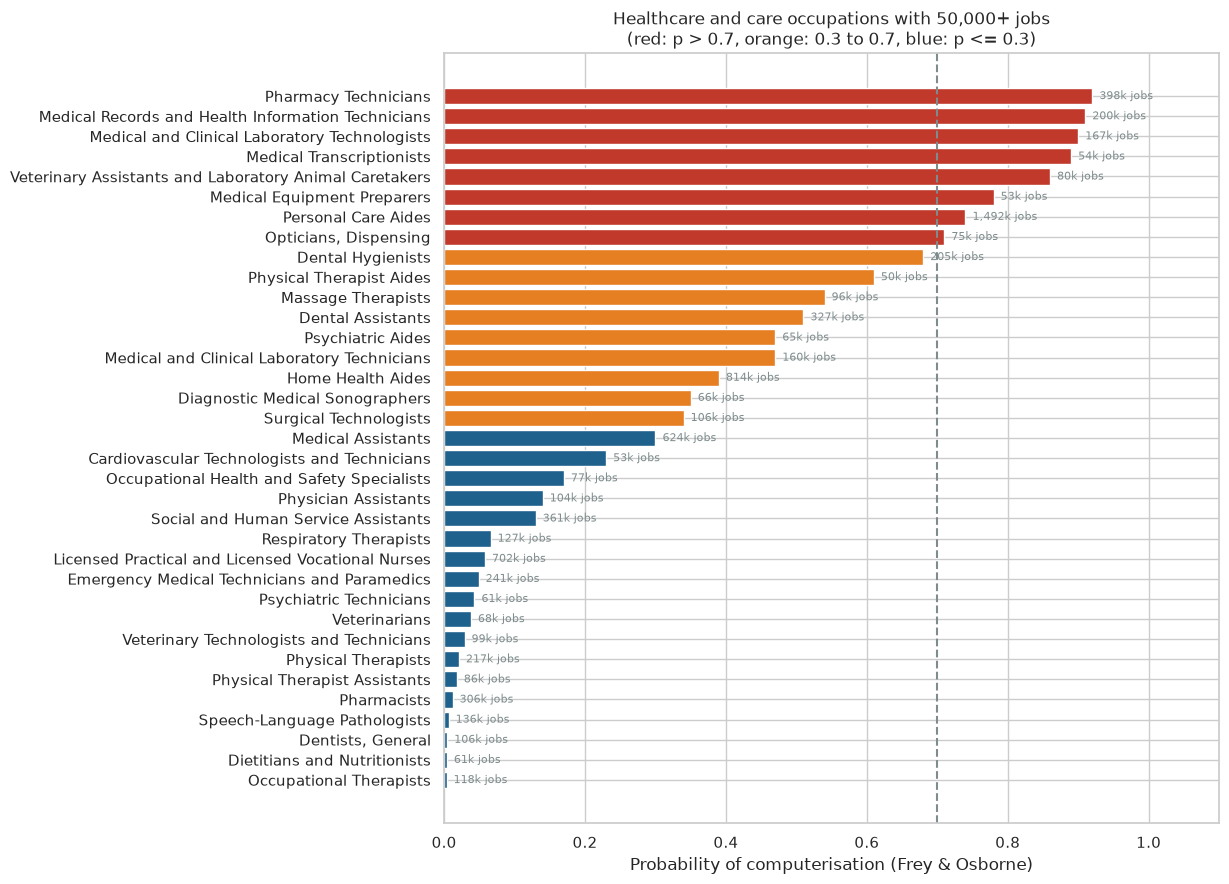

In [19]:
plot = hc[hc.EMPLOYMENT >= 50_000].sort_values("Probability")
fig, ax = plt.subplots(figsize=(10, 10))
colors = [ACCENT if p > HIGH_RISK_THRESHOLD else ("#E67E22" if p > 0.3 else ACCENT2) for p in plot.Probability]
ax.barh(short(plot.Occupation, 55), plot.Probability, color=colors)
for y, (p, e) in enumerate(zip(plot.Probability, plot.EMPLOYMENT)):
    ax.text(p + 0.01, y, f"{e/1000:,.0f}k jobs", va="center", fontsize=8, color=GREY)
ax.axvline(HIGH_RISK_THRESHOLD, ls="--", color=GREY)
ax.set(xlim=(0, 1.1), xlabel="Probability of computerisation (Frey & Osborne)", title="Healthcare and care occupations with 50,000+ jobs\n(red: p > 0.7, orange: 0.3 to 0.7, blue: p <= 0.3)")
save(fig, "11_healthcare_occupations.png")

## 8. Summary

* **RQ1.** The occupations with the highest probability of computerisation are routine clerical, sales and production jobs (several at 0.99). The occupations with the most exposed jobs are large, lower-wage occupations such as retail salespersons, cashiers and food preparation and serving workers, which matches the dissertation's ranking once exposure is computed correctly.
* **RQ2.** Risk differs strongly by occupational group. Food preparation and serving (employment-weighted mean 0.88), sales, production, office and administrative support, and transportation have the highest employment-weighted probabilities. Community and social service (0.05), computer and mathematical (0.09) and management (0.14) have the lowest. Healthcare practitioners and technical (0.28) and healthcare support (0.42) are below the all-occupation figure of 0.61.
* **RQ3.** Measured correctly (employment-weighted probability), the 50 states range from 0.55 (Massachusetts) to 0.66 (Nevada), and the District of Columbia is lowest at 0.45. California ranks 41st of 51, so the dissertation's ranking with California first reflected state size, not risk. Large states still have the most *workers* in high-risk occupations (California has about 7.2 million).
* **RQ4.** The dissertation's R-squared of 0.82 reproduces exactly but comes from target leakage. In the corrected setup, wage, employment and occupational-group data explain about half of the variation in automation probability on held-out occupations (test R-squared about 0.49 to 0.51). Random forest is marginally best on the test set and linear regression is best in cross-validation, so the three models perform similarly, and all clearly beat the baseline.

Limitations are listed in the README.